# Setup

## Imports

In [49]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [50]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [51]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE118767_10x_3cl' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSG00000233997,ENSG00000280233,ENSG00000250141,ENSG00000091181,ENSG00000236818,ENSG00000267724,ENSG00000235091,ENSG00000254519,ENSG00000257057,ENSG00000218757,...,ENSG00000251999,ENSG00000279442,ENSG00000146147,ENSG00000243302,ENSG00000232227,ENSG00000054219,ENSG00000229238,ENSG00000137691,ENSG00000229302,ENSG00000223839
cell_id,,,,,,,,,,,,,,,,,,,,,
CELL_000001,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
CELL_000003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CELL_000004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CELL_000005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CELL_000006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CELL_000939,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,2,0,0
CELL_000943,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CELL_000946,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Dataset config

In [52]:
DATASET_DIR = DATASETS_DIR / 'GSE118767_10x_3cl'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.13, min_gene_max_count=2, min_count_threshold=None, max_count_threshold=None, min_gene_threshold=None, max_gene_threshold=None)

# Quality Control

In [53]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

count_depth           202535.000
n_genes                 9348.000
mito_fraction              0.038
rrna_fraction              0.010
apoptosis_fraction         0.016
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
CELL_000001,487864,11237,0.043,0.009,0.013
CELL_000003,473831,11203,0.041,0.009,0.015
CELL_000004,467714,11237,0.028,0.007,0.018
CELL_000005,450623,10920,0.029,0.006,0.015
CELL_000006,429971,11157,0.026,0.003,0.015


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
CELL_000935,98149,7636,0.075,0.029,0.016
CELL_000943,97999,7334,0.054,0.020,0.017
CELL_000946,97506,7315,0.039,0.008,0.017
CELL_000965,78579,7357,0.031,0.012,0.014
CELL_000955,77869,6809,0.052,0.022,0.014


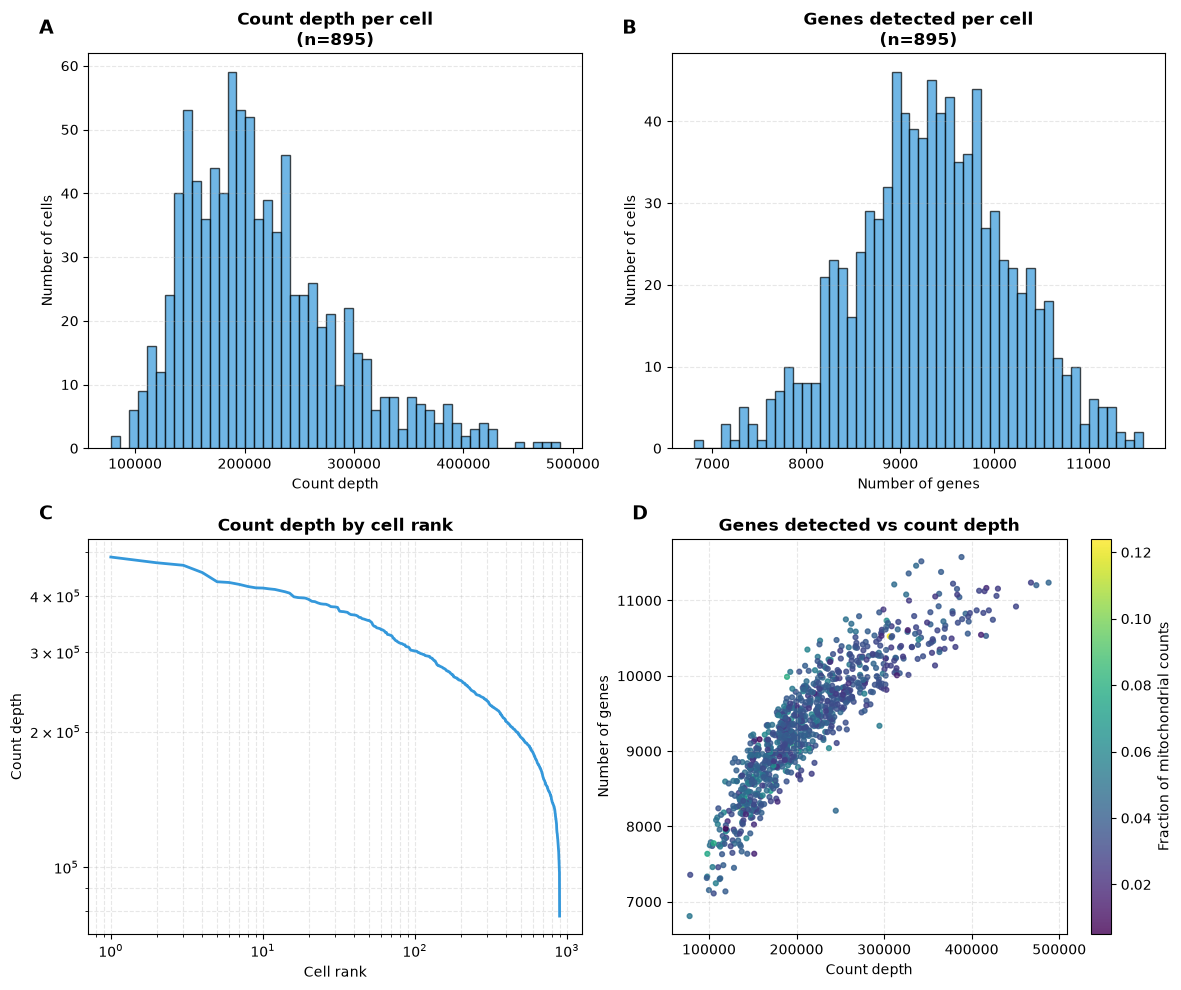

In [54]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    min_count_threshold=preprocessing_config.min_count_threshold,  # minimum count depth, set in the dataset config
    max_count_threshold=preprocessing_config.max_count_threshold,  # maximum count depth, set in the dataset config
    min_gene_threshold=preprocessing_config.min_gene_threshold,    # minimum genes per cell, set in the dataset config
    max_gene_threshold=preprocessing_config.max_gene_threshold,    # maximum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

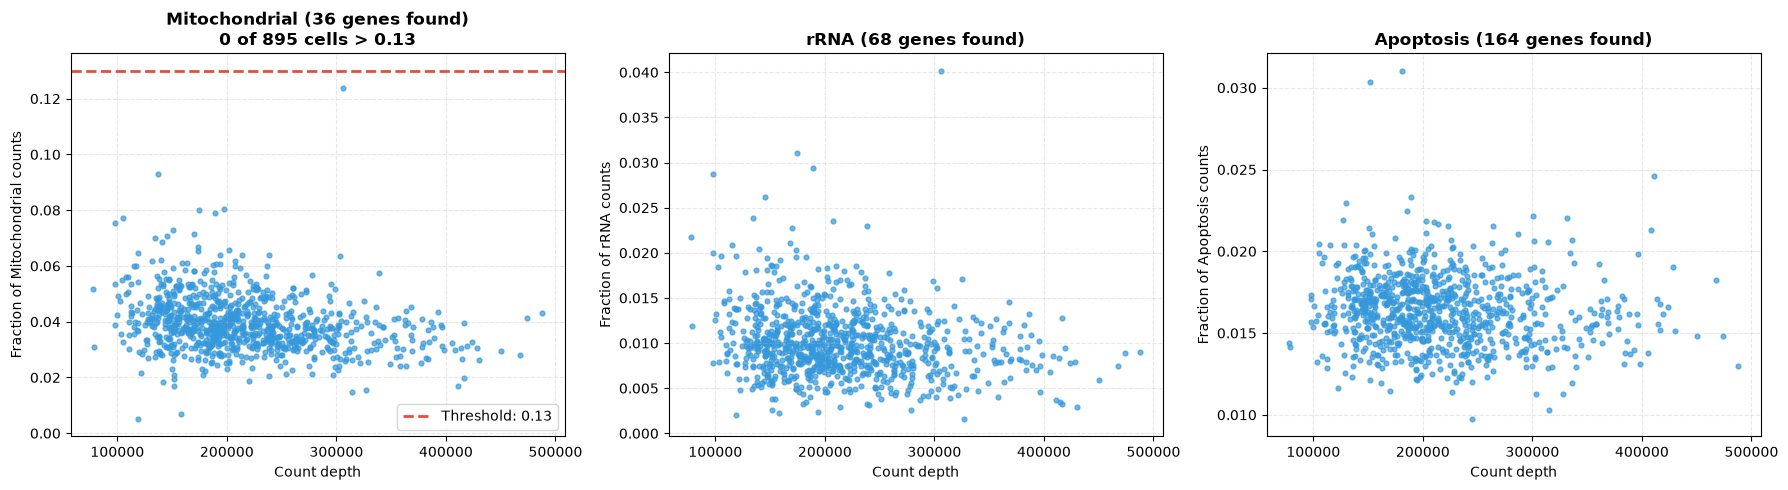

In [55]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [56]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 33456, unique gene names: 33456
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [57]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 823 / 33456
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 823, e.g. ['ENSG00000229191', 'ENSG00000250670', 'ENSG00000232324', 'ENSG00000256763', 'ENSG00000254100']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [58]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 68 / 33456
  share of all counts: 0.010


,total_counts
ENSG00000210082,1621802
ENSG00000211459,268476
ENSG00000202502,528
ENSG00000199804,90
ENSG00000201035,41
...,...
ENSG00000200275,0
ENSG00000201610,0
ENSG00000200687,0
ENSG00000223203,0


## Filtering pipeline

In [59]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(895, 26566)

### Low expression genes

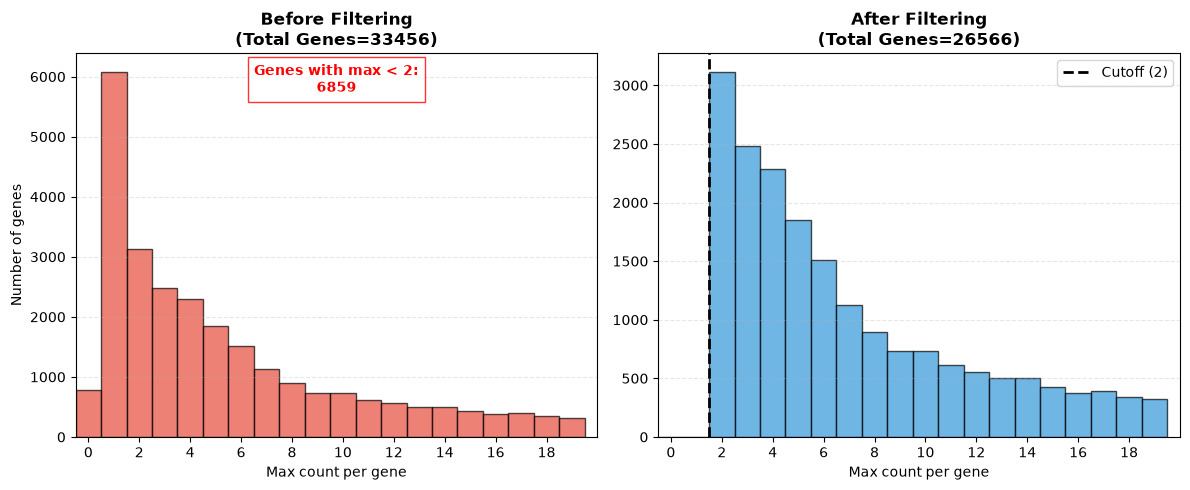

In [60]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

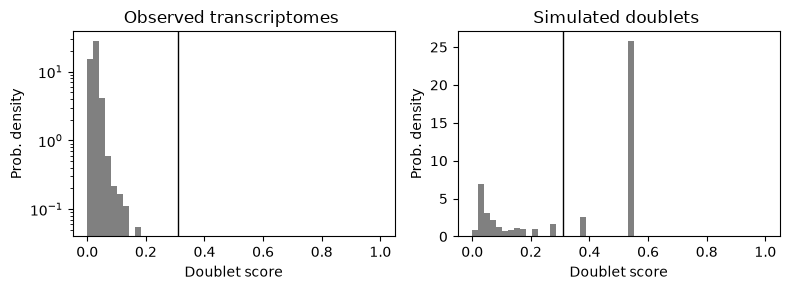

Cells removed as doublets: 0 / 895


In [61]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [62]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(895, 26566)

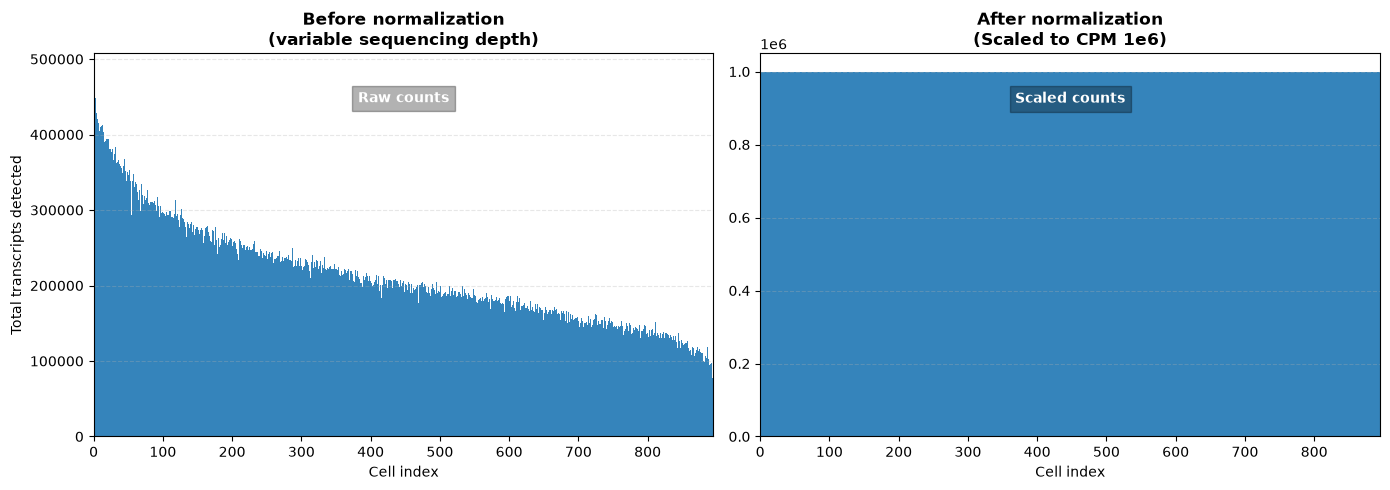

In [63]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [64]:
logged_data = log_transform(normalized_data)

logged_data.shape

(895, 26566)

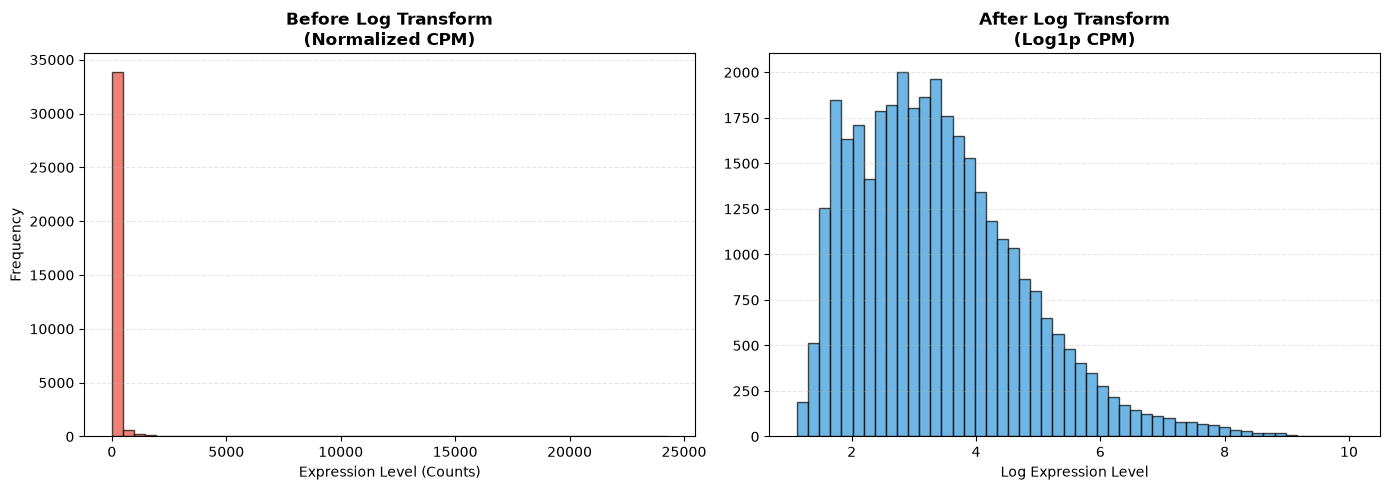

In [65]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [66]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(895, 26566)

In [67]:
pearsons_data.head()

,ENSG00000265987,ENSG00000254298,ENSG00000206687,ENSG00000178462,ENSG00000228559,ENSG00000159723,ENSG00000279685,ENSG00000232767,ENSG00000252507,ENSG00000256783,...,ENSG00000225756,ENSG00000133454,ENSG00000238098,ENSG00000232028,ENSG00000267943,ENSG00000133433,ENSG00000146147,ENSG00000232227,ENSG00000054219,ENSG00000137691
cell_id,,,,,,,,,,,,,,,,,,,,,
CELL_000001,-0.071208,-0.087211,-0.071208,-0.071208,-0.100701,-0.071208,-0.087211,-0.071208,-0.087211,-0.087211,...,-0.087211,-0.071208,-1.249953,-0.207566,-0.087211,-0.527373,-0.112586,-0.087211,1.113828,-2.105732
CELL_000003,-0.070181,-0.085952,-0.070181,-0.070181,-0.099248,-0.070181,-0.085952,-0.070181,-0.085952,-0.085952,...,-0.085952,-0.070181,-1.232191,-0.204572,-0.085952,-0.519783,-0.110961,-0.085952,-0.577772,-2.076664
CELL_000004,-0.069780,-0.085461,-0.069780,-0.069780,-0.098681,-0.069780,-0.085461,-0.069780,-0.085461,-0.085461,...,-0.085461,-0.069780,-1.225259,-0.203404,-0.085461,-0.516822,-0.110328,-0.085461,-0.574483,-2.065310
CELL_000005,-0.068547,-0.083952,-0.068547,-0.068547,-0.096938,-0.068547,-0.083952,-0.068547,-0.083952,-0.083952,...,-0.083952,-0.068547,0.433217,-0.199812,-0.083952,-0.507716,-0.108379,-0.083952,-0.564367,-2.030341
CELL_000006,-0.067056,-0.082125,-0.067056,-0.067056,-0.094829,-0.067056,-0.082125,-0.067056,-0.082125,-0.082125,...,-0.082125,-0.067056,-1.178103,-0.195467,-0.082125,1.511639,-0.106021,-0.082125,-0.552125,-1.987929
